# GridironIQ · What the cap says about winning

Using the cleaned 2011–2024 cap data (see [`01_cap_eda.ipynb`](01_cap_eda.ipynb)), this notebook presents the findings — every figure comes straight from the `gridiron.modeling` package, nothing is re-implemented here.

In [1]:
import sys
from pathlib import Path
# make the gridiron package importable whether run from the repo root or notebooks/
_root = Path.cwd().resolve()
sys.path.insert(0, str(_root if (_root / "gridiron").exists() else _root.parent))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_curve, auc
from sklearn.model_selection import StratifiedKFold, cross_val_predict

from gridiron.modeling import cap_efficiency, clustering, ml_pipeline

sns.set_theme(style="whitegrid", palette="deep")

## 1. Do champions over- or under-pay by position?

The headline. `champion_premium` compares Super Bowl winners' positional cap share against the league average (2011–2024).

,league_avg,finalist_avg,champion_avg,premium
pos_group,,,,
CB,0.0988,0.0805,0.0785,-2.03
LB,0.0773,0.0725,0.0589,-1.85
OL,0.1843,0.1780,0.1716,-1.27
RB,0.0549,0.0527,0.0444,-1.06
IDL,0.1039,0.1049,0.1032,-0.07
SPEC,0.0290,0.0311,0.0315,0.26
WR,0.1113,0.1103,0.1157,0.44
S,0.0689,0.0771,0.0764,0.75
EDGE,0.1168,0.1186,0.1299,1.32


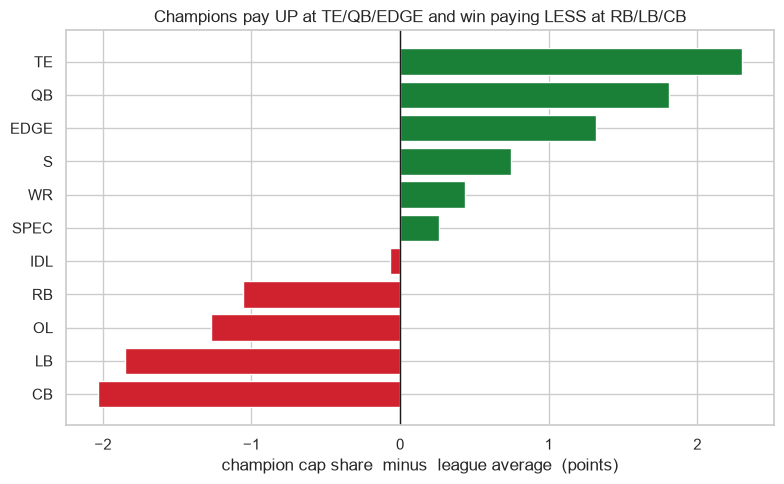

In [2]:
prem = cap_efficiency.champion_premium().sort_values("premium")
colors = ["#cf222e" if v < 0 else "#1a7f37" for v in prem["premium"]]

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(prem.index, prem["premium"] * 100, color=colors)
ax.axvline(0, color="k", lw=1)
ax.set(xlabel="champion cap share  minus  league average  (points)",
       title="Champions pay UP at TE/QB/EDGE and win paying LESS at RB/LB/CB")
plt.tight_layout()
prem.assign(premium=(prem["premium"] * 100).round(2))

And the win-correlation verdict (`efficiency_verdict`) — which positions' spending actually tracks winning, with a plain-English call:

In [3]:
cap_efficiency.efficiency_verdict()

,champion_premium,corr_win,verdict
pos_group,,,
TE,0.0230,0.1557,underpaid (worth paying up)
QB,0.0181,0.0661,underpaid (worth paying up)
EDGE,0.0132,0.0464,underpaid (worth paying up)
S,0.0075,0.0512,underpaid (worth paying up)
WR,0.0044,0.0311,fairly paid
SPEC,0.0026,0.0217,fairly paid
IDL,-0.0007,0.0087,fairly paid
RB,-0.0106,-0.0480,overpaid leaguewide
OL,-0.0127,-0.0089,overpaid leaguewide


## 2. Roster archetypes (k-means on spending profiles)

Cluster every team-season by *how* it splits its cap, then score each archetype by how often it reaches and wins the Super Bowl.

In [4]:
res = clustering.cluster_archetypes(k=5)
res.success.sort_values("sb_appearance_rate", ascending=False)

,n_team_seasons,sb_appearance_rate,sb_win_rate
archetype,,,
0,120,0.083,0.058
4,65,0.062,0.015
2,91,0.055,0.011
1,74,0.054,0.027
3,96,0.052,0.031


,QB,RB,WR,TE,OL,IDL,EDGE,LB,CB,S,SPEC,label
archetype,,,,,,,,,,,,
0,0.127,0.038,0.085,0.049,0.156,0.071,0.076,0.075,0.070,0.069,0.027,QB + S
1,0.059,0.027,0.065,0.032,0.141,0.061,0.068,0.056,0.072,0.033,0.012,OL + CB
2,0.064,0.040,0.100,0.036,0.140,0.132,0.068,0.054,0.105,0.048,0.022,IDL + CB
3,0.076,0.032,0.113,0.042,0.145,0.074,0.144,0.055,0.080,0.059,0.023,EDGE + WR
4,0.077,0.081,0.063,0.030,0.126,0.061,0.101,0.054,0.056,0.051,0.016,RB + EDGE


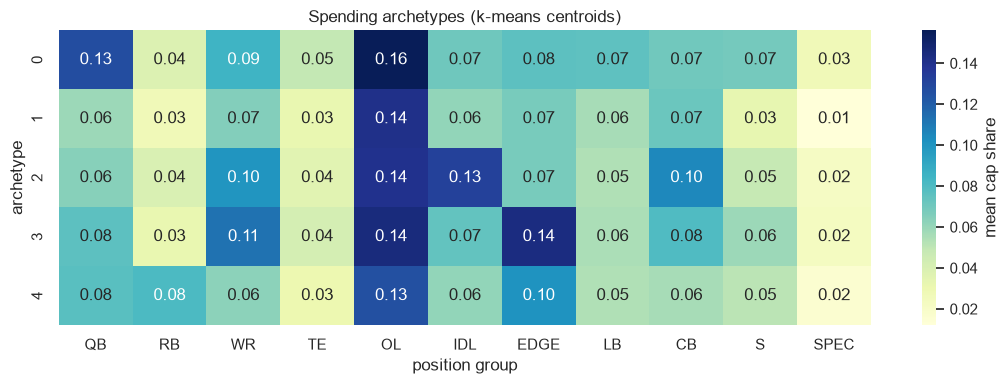

In [5]:
prof = res.profiles.drop(columns=["label"])
fig, ax = plt.subplots(figsize=(11, 4))
sns.heatmap(prof, annot=True, fmt=".2f", cmap="YlGnBu",
            cbar_kws={"label": "mean cap share"}, ax=ax)
ax.set(title="Spending archetypes (k-means centroids)",
       xlabel="position group", ylabel="archetype")
plt.tight_layout()
res.profiles

## 3. Can positional spending predict a Super Bowl *title*?

A gut check on signal, not a betting model. `ml_pipeline` cross-validates a random forest on the positional-share features to pick out the Super Bowl **winner** (`sb_win`); here I draw the honest **out-of-fold** ROC and the permutation feature importances. Only **14 champions** fall in the 2011–2024 window, so the positive class is tiny — read the AUC *with* its spread, not as a point estimate.

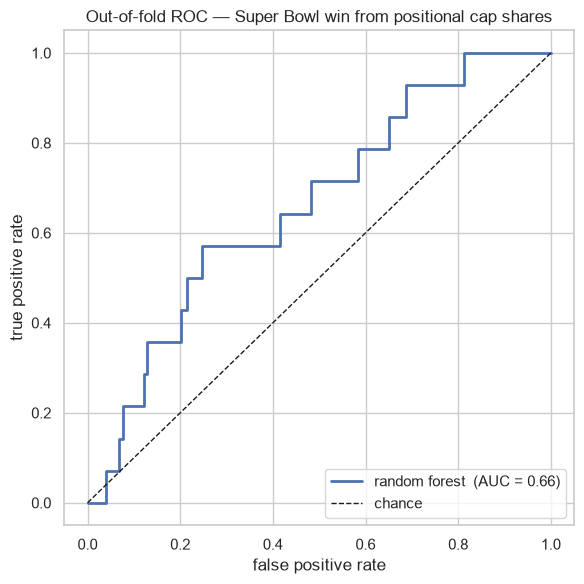

In [6]:
X, y = ml_pipeline.get_xy(target="sb_win")
pipe = ml_pipeline.build_pipeline("rf")
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
proba = cross_val_predict(pipe, X, y, cv=cv, method="predict_proba")[:, 1]
fpr, tpr, _ = roc_curve(y, proba)

fig, ax = plt.subplots(figsize=(6, 6))
ax.plot(fpr, tpr, lw=2, label=f"random forest  (AUC = {auc(fpr, tpr):.2f})")
ax.plot([0, 1], [0, 1], "k--", lw=1, label="chance")
ax.set(xlabel="false positive rate", ylabel="true positive rate",
       title="Out-of-fold ROC — Super Bowl win from positional cap shares")
ax.legend(loc="lower right")
plt.tight_layout()

5-fold CV AUC: 0.714 +/- 0.126  (n=446, positives=14)


,feature,importance,std
0,pct_TE,0.084069,0.018835
1,pct_WR,0.057507,0.022391
2,pct_CB,0.019816,0.010568
3,pct_LB,0.005853,0.001896
4,pct_S,0.005597,0.002017
5,pct_OL,0.005134,0.001532
6,pct_EDGE,0.002422,0.001326
7,pct_QB,0.000868,0.000640
8,pct_RB,0.000604,0.000392
9,pct_SPEC,0.000496,0.000291


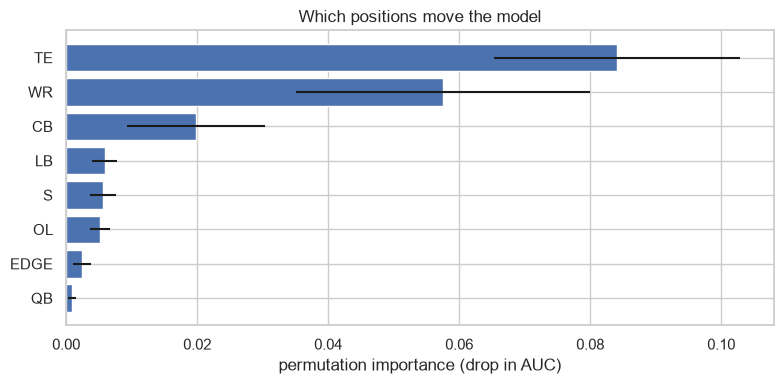

In [7]:
report = ml_pipeline.train_and_report(target="sb_win", model="rf")
print(f"5-fold CV AUC: {report.cv_auc_mean:.3f} +/- {report.cv_auc_std:.3f}  "
      f"(n={report.n_samples}, positives={report.n_positive})")

imp = report.importances.head(8).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(imp["feature"].str.replace("pct_", ""), imp["importance"], xerr=imp["std"])
ax.set(xlabel="permutation importance (drop in AUC)",
       title="Which positions move the model")
plt.tight_layout()
report.importances

## Takeaways

- Champions **pay up** at TE/QB/EDGE and win **spending less** at RB/LB/CB — the thesis, quantified.
- Spending *shape* clusters into archetypes with very different title rates.
- Positional cap shares carry real (if modest) signal for a Super Bowl **title** (~0.71 five-fold AUC, but ±0.13 on just 14 champions) — cap allocation matters, it isn't destiny, and the sample is small enough to stay humble.

All figures come straight from the `gridiron.modeling` package — the same code the Streamlit app and CLI use.